# The exchange economy

**Lecture 12 · Wednesday, 2 December 2026 · Notebook 1 of 1**

In Lecture 11 we took a model of a *whole economy over time* from equations to results. Now we use the same recipe for a **market**: two people own some goods and may trade. At which price do their plans fit together? This is a **Walras equilibrium**.

**The focus is programming, not economic theory.** We use a class (Lecture 3), vectorized NumPy (Lecture 4), plots (Lecture 5), a root-finder (Lecture 7), our own loop-based algorithm, and known answers as tests.

## How to work

| Recording | Sections |
| --- | --- |
| Video 12A: The model as a class | 1–2 |
| Video 12B: The equilibrium price | 3–4 |
| Video 12C: The Edgeworth box and an auction | 5–6 |

The questions for class are in **`Exercises.ipynb`**. **Before class (Tuesday 1 December, 23:59):** solve warm-ups **W1–W2** there, enter your answers in the Absalon quiz and upload the notebook. Class is on Wednesday 2 December, together with Lecture 11.

**Table of contents**<a id='toc0_'></a>
- 1. [The model](#toc1_)
- 2. [The model as a class](#toc2_)
- 3. [The equilibrium price](#toc3_)
- 4. [Testing, and who gains from trade](#toc4_)
- 5. [The Edgeworth box](#toc5_)
- 6. [An auction: tâtonnement](#toc6_)
- 7. [Summary](#toc7_)

<a id='video-12a'></a>
> **Start Video 12A**  
> Question: what do two people with different tastes want to trade?

## 1. <a id='toc1_'></a>[The model](#toc0_)

**Two people and two goods.** The two people are called $A$ and $B$. The two goods are called good 1 and good 2 - think of them as *apples* and *bananas*.

**Endowments.** Nobody produces anything. The goods are simply there already, and each person **owns** some of them from the start. This is called the *endowment*:

* $\omega_1^A$ and $\omega_2^A$: what $A$ owns of good 1 and good 2
* $\omega_1^B$ and $\omega_2^B$: what $B$ owns

We measure the goods so that there is **exactly one unit of each good in total**. Whatever $A$ does not own, $B$ owns:

$$ \omega_1^B = 1-\omega_1^A, \qquad \omega_2^B = 1-\omega_2^A $$

**Consumption.** After trading, $A$ ends up with $x_1^A$ of good 1 and $x_2^A$ of good 2, and $B$ with $x_1^B$ and $x_2^B$. Nothing is created or destroyed, so what they end up with must still add up to one of each good.

**Preferences.** How much a person likes a basket of goods is measured by a **utility function**. A higher number means a more attractive basket. We use

$$ u^A(x_1,x_2) = x_1^{\alpha}x_2^{1-\alpha}, \qquad u^B(x_1,x_2) = x_1^{\beta}x_2^{1-\beta}, \qquad \alpha,\beta \in (0,1) $$

The only thing you need to read out of these formulas is:

* both people want **more** of both goods,
* $\alpha$ says how much $A$ cares about good 1 relative to good 2, and $\beta$ says the same for $B$,
* if $\alpha \neq \beta$ the two people have **different tastes** - which is exactly why there is something to gain from trading.

**Prices.** Trade happens at a price. Let $p_1$ be the price of good 1 and $p_2$ the price of good 2. Only the **relative** price matters - doubling both prices changes nothing, because everybody both buys and sells. So we are free to fix

$$ p_2 = 1 $$

and measure everything in units of good 2. Then $p_1$ is the *only* unknown in the whole model. This choice is called a **numeraire**.

**Income.** At the price $p_1$, what $A$ owns is worth

$$ m^A = p_1\omega_1^A + \omega_2^A $$

and this is what she has to spend. Similarly for $B$.

**Demand.** Each person buys the basket she likes best among those she can afford. For the utility functions above the answer has a very simple form: **spend the share $\alpha$ of your income on good 1 and the rest on good 2**. Dividing by the prices to get quantities,

$$
\begin{aligned}
x_1^{A}(p_1) &= \alpha\frac{m^A}{p_1}, &\qquad x_2^{A}(p_1) &= (1-\alpha)\,m^A \\
x_1^{B}(p_1) &= \beta\frac{m^B}{p_1}, &\qquad x_2^{B}(p_1) &= (1-\beta)\,m^B
\end{aligned}
$$

(This can be derived with pen and paper by maximizing $u$ subject to the budget - we just take the result as given here.)

Note the two forces in $x_1^A(p_1)$: a higher $p_1$ makes good 1 more **expensive** (the $p_1$ in the denominator), but it also makes $A$ **richer** if she owns a lot of good 1 (the $p_1$ inside $m^A$).

**Equilibrium.** A price is an **equilibrium price** when the plans of the two people fit together: they together want to consume exactly what exists. Define **excess demand** as *wanted minus available*,

$$
\begin{aligned}
\varepsilon_1(p_1) &= x_1^{A}(p_1) + x_1^{B}(p_1) - 1 \\
\varepsilon_2(p_1) &= x_2^{A}(p_1) + x_2^{B}(p_1) - 1
\end{aligned}
$$

The **equilibrium price** $p_1^{\ast}$ is the price where excess demand is zero. This is called a **Walras equilibrium**.

**One equation is enough.** Everybody spends exactly her income, so the *value* of what is demanded always equals the *value* of what is owned, at any price:

$$ p_1\varepsilon_1(p_1) + \varepsilon_2(p_1) = 0 \qquad \text{for all } p_1 $$

This is **Walras' law**. It means that if market 1 clears then market 2 clears automatically. So we only have to solve **one equation in one unknown** - and we get a free test of our code.

## 2. <a id='toc2_'></a>[The model as a class](#toc0_)

The class lives in **`exchange.py`**, like `solow.py` in Lecture 11: parameters are attributes with default values, equations are methods.

| Method | Returns |
| --- | --- |
| `utility_A(x1, x2)`, `utility_B(x1, x2)` | utility |
| `demand_A(p1)`, `demand_B(p1)` | demand $(x_1, x_2)$ |
| `excess_demand(p1)` | $(\varepsilon_1, \varepsilon_2)$ |
| `equilibrium_price()` | $p_1^*$ from the formula (Section 3) |
| `solve_equilibrium_price()` | $p_1^*$ with a root-finder |

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from exchange import ExchangeEconomy
from edgeworth_box import edgeworth_box, plot_indifference_A, plot_indifference_B

In [2]:
model = ExchangeEconomy()
print(f'alpha = {model.alpha:.2f}, beta = {model.beta:.2f}')
print(f'A owns ({model.w1A:.2f}, {model.w2A:.2f}); B owns ({1 - model.w1A:.2f}, {1 - model.w2A:.2f})')

alpha = 0.33, beta = 0.67
A owns (0.80, 0.30); B owns (0.20, 0.70)


Read it as a story: $A$ owns most of good 1 but spends only a third of her income on it. $B$ is the other way around. They should have something to trade.

### Look at excess demand first

Before solving anything, we **look** at the equation. The demand functions use only arithmetic, so they work on a whole array of prices at once (Lecture 4).

**Pause and predict:** is excess demand for good 1 positive or negative at a very low price?

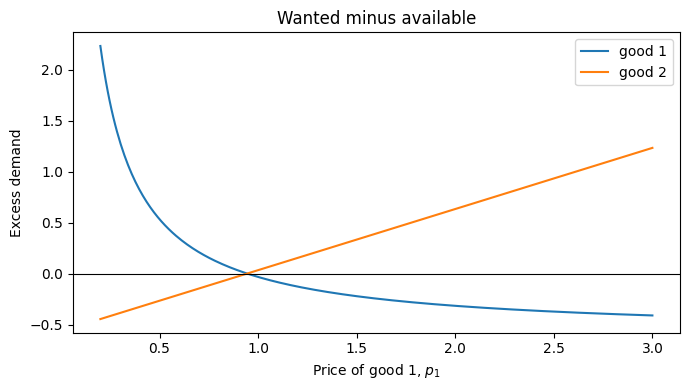

In [3]:
p1_grid = np.linspace(0.2, 3.0, 300)
eps1, eps2 = model.excess_demand(p1_grid)      # one excess demand per price in the grid

fig = plt.figure(figsize=(7, 4))
ax = fig.add_subplot(1, 1, 1)
ax.plot(p1_grid, eps1, label='good 1')
ax.plot(p1_grid, eps2, label='good 2')
ax.axhline(0.0, color='black', linewidth=0.8)
ax.set_xlabel('Price of good 1, $p_1$')
ax.set_ylabel('Excess demand')
ax.set_title('Wanted minus available')
ax.legend()
fig.tight_layout()
plt.show()

At a low price, everyone wants a lot of good 1: positive excess demand. At a high price, too little is wanted. Somewhere in between, excess demand for good 1 is zero, and **at the same price** it is zero for good 2 as well.

**Walras' law** says that $p_1\varepsilon_1 + \varepsilon_2 = 0$ at **every** price. It gives us a free test of the code:

In [4]:
assert np.allclose(p1_grid*eps1 + eps2, 0.0), "Walras' law fails"
print("Walras' law holds at all", p1_grid.size, 'prices')

Walras' law holds at all 300 prices


> **Stop Video 12A.** You can use the model's class, look at excess demand and test the code with Walras' law.

<a id='video-12b'></a>
> **Start Video 12B**  
> Question: which price clears the market, and who gains from trading?

## 3. <a id='toc3_'></a>[The equilibrium price](#toc0_)

**Solving by hand.** Insert the demand functions in $\varepsilon_1(p_1) = 0$ and multiply by $p_1$:

$$ \alpha(p_1\omega_1^A+\omega_2^A) + \beta(p_1\omega_1^B+\omega_2^B) = p_1 $$

Collecting the terms with $p_1$ on one side and using $\omega_1^A+\omega_1^B=1$ gives

$$ \boxed{\;p_1^{\ast} = \frac{\alpha\omega_2^A + \beta\omega_2^B}{(1-\alpha)\omega_1^A + (1-\beta)\omega_1^B}\;} $$

As in the Solow lecture: having an answer we can compute by hand is *very* useful - we will use it to test everything else.

In code, twice: with the formula, and with `brentq` on excess demand for good 1 (Lecture 7).

In [5]:
p1_formula = model.equilibrium_price()
p1_numerical = model.solve_equilibrium_price()

print(f'p1* from the formula:     {p1_formula:.8f}')
print(f'p1* from the root-finder: {p1_numerical:.8f}')
assert np.isclose(p1_formula, p1_numerical), 'formula and root-finder disagree'

p1* from the formula:     0.94444444
p1* from the root-finder: 0.94444444


## 4. <a id='toc4_'></a>[Testing, and who gains from trade](#toc0_)

At the equilibrium price, **both** markets must clear: together, A and B consume exactly what exists.

In [6]:
p1 = p1_formula
x1A, x2A = model.demand_A(p1)
x1B, x2B = model.demand_B(p1)

print(f'A consumes ({x1A:.4f}, {x2A:.4f})')
print(f'B consumes ({x1B:.4f}, {x2B:.4f})')

assert np.isclose(x1A + x1B, 1.0), 'market for good 1 does not clear'
assert np.isclose(x2A + x2B, 1.0), 'market for good 2 does not clear'
print('both markets clear')

A consumes (0.3725, 0.7037)
B consumes (0.6275, 0.2963)
both markets clear


**Pause and predict:** who gains from trading, A, B or both?

Without trade, each person consumes her endowment. With trade, she consumes her equilibrium demand. Compare utilities:

In [7]:
uA_no_trade = model.utility_A(model.w1A, model.w2A)
uB_no_trade = model.utility_B(1 - model.w1A, 1 - model.w2A)
uA_trade = model.utility_A(x1A, x2A)
uB_trade = model.utility_B(x1B, x2B)

print(f'A: utility {uA_no_trade:.4f} without trade, {uA_trade:.4f} with trade')
print(f'B: utility {uB_no_trade:.4f} without trade, {uB_trade:.4f} with trade')

A: utility 0.4160 without trade, 0.5693 with trade
B: utility 0.3037 without trade, 0.4886 with trade


**Both gain.** Nobody is forced to trade, so a trade happens only if it makes each side better off. The test: if A and B had the **same** tastes and endowments, there would be nothing to gain.

> **Stop Video 12B.** You can find the equilibrium price in two ways, check that markets clear and measure the gains from trade.

<a id='video-12c'></a>
> **Start Video 12C**  
> Question: how can we *see* the trade, and how could a market find the price by itself?

## 5. <a id='toc5_'></a>[The Edgeworth box](#toc0_)

The **Edgeworth box** shows both people in one figure. Its width is the one unit of good 1, its height the one unit of good 2. A point in the box is an allocation: A's consumption measured from the **lower-left** corner, B's from the **upper-right** corner, so they always add up to what exists.

The file `edgeworth_box.py` draws the empty box and the indifference curves; we only add the points.

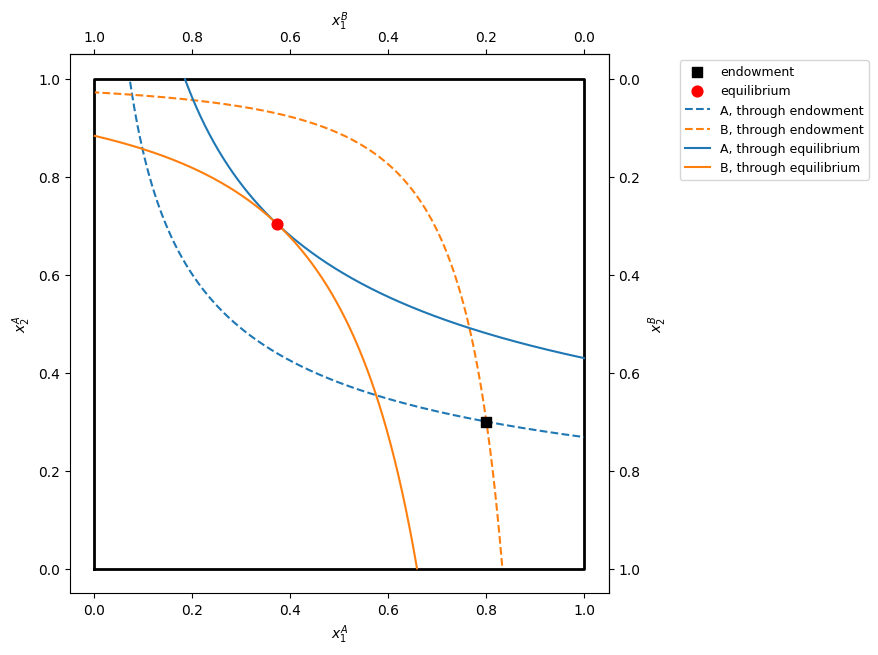

In [8]:
fig, ax = edgeworth_box()

# a. endowment: where they start
ax.scatter(model.w1A, model.w2A, marker='s', s=60, color='black', zorder=3, label='endowment')

# b. equilibrium: where they end
ax.scatter(x1A, x2A, s=60, color='red', zorder=3, label='equilibrium')

# c. indifference curves through the endowment
plot_indifference_A(ax, model, model.w1A, model.w2A, color='C0', linestyle='--', label='A, through endowment')
plot_indifference_B(ax, model, 1 - model.w1A, 1 - model.w2A, color='C1', linestyle='--', label='B, through endowment')

# d. indifference curves through the equilibrium
plot_indifference_A(ax, model, x1A, x2A, color='C0', label='A, through equilibrium')
plot_indifference_B(ax, model, x1B, x2B, color='C1', label='B, through equilibrium')

ax.legend(loc='upper left', fontsize=9, bbox_to_anchor=(1.12, 1.0))
plt.show()

The two dashed curves enclose a lens: every allocation inside it is better for **both**. The equilibrium lies inside the lens, where the two solid curves just touch: no further trade can make both better off.

## 6. <a id='toc6_'></a>[An auction: tâtonnement](#toc0_)

A root-finder is one way to find $p_1^*$. Walras imagined another: an **auctioneer** calls a price, listens to excess demand, and adjusts:

- too much wanted ($\varepsilon_1 > 0$): raise the price;
- too little wanted ($\varepsilon_1 < 0$): lower it.

$$p_1 \leftarrow p_1 + \nu\,\varepsilon_1(p_1),$$

where $\nu > 0$ is the **step size**. This is *tâtonnement* (French for groping). It is a simple loop, with a stopping rule and a maximum number of rounds:

In [9]:
def tatonnement(model, p1, nu, tol=1e-8, maxiter=500):
    """Adjust the price until excess demand for good 1 is below tol.

    Returns the final price, the number of rounds and True if it converged.
    """

    for k in range(maxiter):
        eps1 = model.excess_demand_good1(p1)
        if np.abs(eps1) < tol:
            return p1, k, True
        p1 = p1 + nu*eps1
        if p1 <= 0:                    # a price cannot be negative
            return p1, k, False

    return p1, maxiter, False


p1_tat, rounds, converged = tatonnement(model, p1=2.0, nu=0.5)
print(f'price {p1_tat:.6f} after {rounds} rounds, converged: {converged} (formula: {p1_formula:.6f})')

price 0.944444 after 52 rounds, converged: True (formula: 0.944444)


**Pause and predict:** is a bigger step always faster?

In [10]:
for nu in [0.1, 0.5, 1.0, 2.0, 4.0]:
    p1_tat, rounds, converged = tatonnement(model, p1=2.0, nu=nu)
    print(f'nu = {nu:3.1f}: {rounds:3d} rounds, converged: {converged}, price {p1_tat:.4f}')

nu = 0.1: 293 rounds, converged: True, price 0.9444
nu = 0.5:  52 rounds, converged: True, price 0.9444
nu = 1.0:  21 rounds, converged: True, price 0.9444
nu = 2.0:  14 rounds, converged: True, price 0.9444
nu = 4.0: 500 rounds, converged: False, price 1.9160


Up to a point, larger steps are faster. With $\nu = 4$ the auctioneer **overshoots**: each correction jumps past the equilibrium, and the price never settles. Always check whether an algorithm converged; never trust its last value blindly.

## 7. <a id='toc7_'></a>[Summary](#toc0_)

| Step | Tool | Lecture |
| --- | --- | --- |
| write the model | a class in a `.py` file | 3 |
| look before solving | excess demand on a price grid, a plot | 4, 5 |
| test | Walras' law, market clearing, `assert` | 11 |
| solve | the formula, and `brentq` | 7 |
| an algorithm of our own | a loop with a stopping rule | 3 |

**The same recipe as for the Solow model:** write the model as a class, test it where you know the answer, then use it. The model project asks you to do exactly this for both models.

> **Stop Video 12C.** End of the recording sequence of the course.